In [1]:
using Revise
using LinearAlgebra
using NLsolve
using Plots
using LaTeXStrings

gr();
# pyplot();
# plotlyjs();

In [2]:
BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N \tilde{J}_{ij} \tanh x_j \ , \\
\tilde{J} &= \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}}{\|\tanh \hat{\bm{x}}\|^2} + \sigma J \, , \\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's run some simulations.

In [4]:
function network_f!(dx, x, J̃, t)
    mul!(dx, J̃, tanh.(x))
    dx .-= x
end

function network_jac!(jac, x, J̃, t)
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = J̃[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= one(eltype(jac))
    end
end

function poor_mans_network_jac!(jac, x, J̃, t, dx)
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, J̃, t)
    for j in 1:N
        xx[j] += dx
        network_f!(fxdx, xx, J̃, t) 
        jac[:, j] = (fxdx - fx) / (xx[j] - x[j])
        xx[j] = x[j]
    end
end

poor_mans_network_jac! (generic function with 1 method)

In [5]:
ftype = Float64

N = 256
s = one(ftype)
x̂ = s * randn(ftype, N)
tx̂ = tanh.(x̂)
Ĵ = x̂ * tx̂' / dot(tx̂, tx̂)
Ĵ[diagind(Ĵ)] .= zero(ftype);

In [6]:
σ = ftype(0.4)
τ = ftype(0.5)

J = ftype(1 / sqrt(N)) * randn(ftype, N, N)
J = SamplingUtils.partially_hermitize(J, τ)
J[diagind(J)] .= zero(ftype)

J̃ = Ĵ + σ * J;

In [7]:
# Verify Jacobian
jaca = similar(J̃)
jacb = similar(J̃)
network_jac!(jaca, x̂, J̃, zero(ftype))
poor_mans_network_jac!(jacb, x̂, J̃, zero(ftype), sqrt(eps(ftype)))
opnorm(jacb - jaca)

6.397565891895276e-7

In [8]:
sol = nlsolve(
    (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
    (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
    x̂;
    method=:newton,
    ftol=sqrt(eps(ftype)),
)
if !converged(sol)
    error("failed to converge")
end
x₀ = sol.zero
jac = similar(J̃)
network_jac!(jac, x₀, J̃, zero(ftype))
jacevs = eigvals(jac)
println(maximum(real(jacevs)))

-0.5227541930844133


In [9]:
R = Diagonal(cosh.(x₀).^(-2))
ensemble = MatrixEnsemble(Ĵ * R - I, σ * I, R, τ)
Mevs = unique(eigvals(ensemble.M))
_J = ftype(1 / sqrt(N)) * randn(ftype, N, N)
_J = SamplingUtils.partially_hermitize(_J, τ)
Aevs = eigvals(ensemble.M + (ensemble.L * _J * ensemble.R));

In [10]:
using LazySets: VPolygon, Bloating, overapproximate, radius

coords = reinterpret(ftype, reshape(Aevs, 1, :));
region = VPolygon(coords);
region = Bloating(region, ftype(0.125) * radius(region));
region = overapproximate(region, ftype(0.01) * radius(region));
bounds = overapproximate(region);

xcenter, ycenter = bounds.center;
xradius, yradius = bounds.radius;
xmin, xmax = xcenter - xradius, xcenter + xradius;
ymin, ymax = ycenter - yradius, ycenter + yradius;
xs = range(xmin, xmax; length=round(Int, 128 * xradius));
ys = range(ymin, ymax; length=round(Int, 128 * yradius));
zs = [[x, y] in region ? complex(x, y) : missing for y in ys, x in xs];

In [11]:
i, j = 13, 62
za = zs[i, j - 1]
zb = zs[i - 1, j]
zc = zs[i, j];

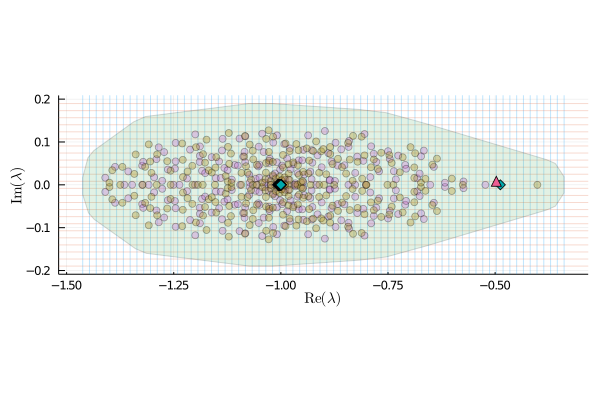

In [12]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

In [13]:
objective = Fixk();
algorithm = Rampδ²(sqrt(2), 16, -16);

In [14]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc, δc² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc);
GaussianSpectralDensities.print_δ²(δc²);
solutionc = solve!(
    solver, zc,
    qc, δc²;
    verbosity=verbosity, store_trace=true,
);
solver = nothing;  # Hand workspace over to GC

 z = -0.513 + i 0.008
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   2.560e+02  2.560e+02   7.458e-03 + i-1.268e-04  3.645e-03
  1.000   1.810e+02  1.810e+02   9.974e-03 + i-1.699e-04  5.065e-03
  1.000   1.280e+02  1.280e+02   1.326e-02 + i-2.263e-04  7.013e-03
  1.000   9.049e+01  9.051e+01   1.752e-02 + i-3.000e-04  9.671e-03
  1.000   6.398e+01  6.400e+01   2.301e-02 + i-3.955e-04  1.327e-02
  1.000   4.523e+01  4.525e+01   3.001e-02 + i-5.184e-04  1.810e-02
  1.000   3.198e+01  3.200e+01   3.884e-02 + i-6.755e-04  2.453e-02
  1.000   2.260e+01  2.263e+01   4.983e-02 + i-8.744e-04  3.297e-02
  1.000   1.597e+01  1.600e+01   6.330e-02 + i-1.124e-03  4.392e-02
  1.000   1.128e+01  1.131e+01   7.957e-02 + i-1.434e-03  5.789e-02
  1.000   7.962e+00  8.000e+00   9.884e-02 + i-1.814e-03  7.541e-02
  1.000   5.613e+00  5.657e+00  

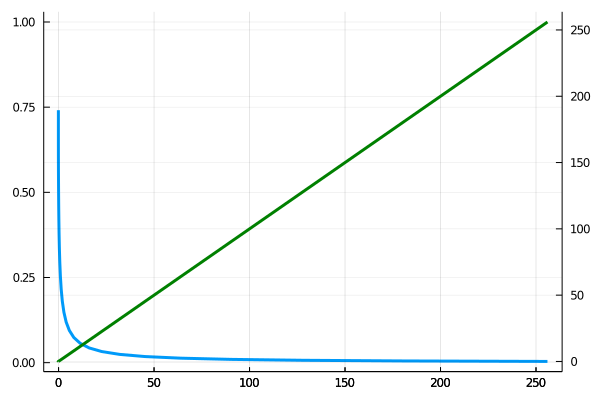

In [15]:
sol = solutionb

plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [16]:
problem = SpectralProblem(ensemble, objective, zs);
solution = solve(problem, algorithm; chunks_per_thread=1);

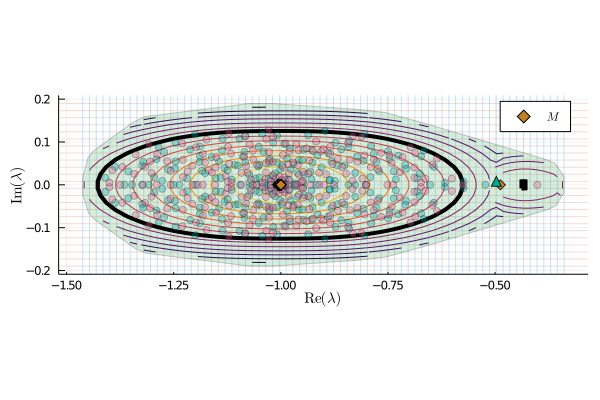

In [17]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.2,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

contour!(p, xs, ys, solution.γ², colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

vline!([0.0], color=:black, label="")

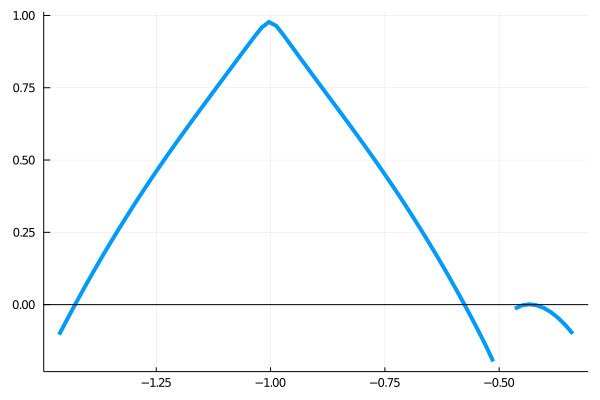

In [18]:
midi = cld(length(ys), 2)
p = plot(xs, solution.γ²[midi, :], linewidth=4, label="")
hline!(p, [0.0], color=:black, label="")

In [19]:
function fpoint(J̃, x₀)
    ftype = eltype(x₀)
    sol = nlsolve(
        (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
        (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
        x₀;
        method=:newton,
        ftol=sqrt(eps(ftype)),
    )
    if !converged(sol)
        error("failed to converge")
    end
    return sol.zero
end

fpoint (generic function with 1 method)

In [20]:
x₀ = x̂
jac_ = similar(J̃)
σs = ftype(0.0):ftype(0.01):ftype(1.5)
evmaxs = fill(ftype(NaN), length(σs))
x₀s = fill(ftype(NaN), (length(x₀), length(σs)))
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    network_jac!(jac_, x₀, J̃, zero(ftype))
    evmaxs[i] = maximum(real(eigvals(jac_)))
end

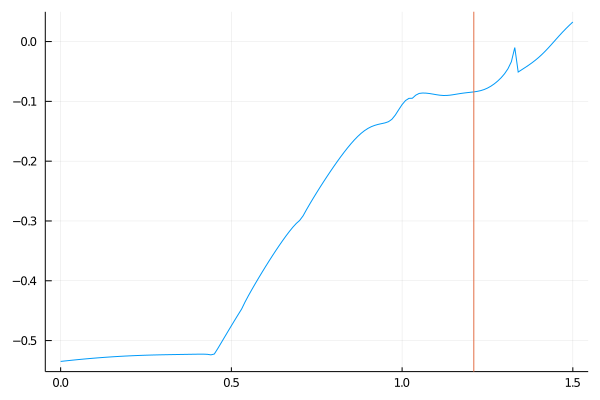

In [21]:
vl = [1.21]
plot(σs, evmaxs, label="")
vline!(vl, label="")

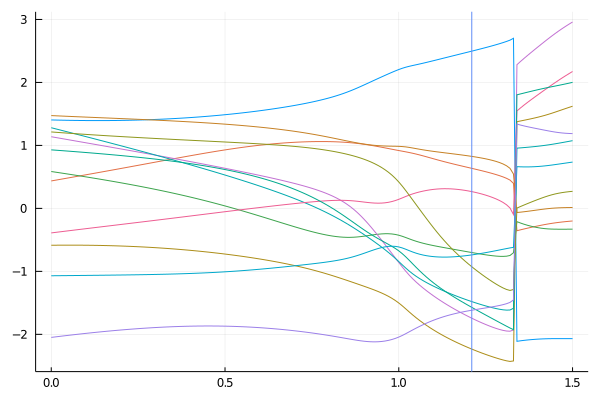

In [22]:
plot(σs, x₀s[1:12, :]', label="")
vline!(vl, label="")

In [23]:
println(repr("text/plain", [σs evmaxs]))

151×2 Array{Float64,2}:
 0.0   -0.534859
 0.01  -0.534228
 0.02  -0.533613
 0.03  -0.533013
 0.04  -0.53243
 0.05  -0.531864
 0.06  -0.531314
 0.07  -0.530782
 0.08  -0.530268
 0.09  -0.529772
 0.1   -0.529295
 0.11  -0.528836
 0.12  -0.528397
 0.13  -0.527977
 0.14  -0.527576
 0.15  -0.527196
 0.16  -0.526834
 0.17  -0.526493
 0.18  -0.526171
 0.19  -0.525869
 0.2   -0.525587
 0.21  -0.525323
 0.22  -0.525079
 0.23  -0.524852
 0.24  -0.524644
 0.25  -0.524453
 0.26  -0.524278
 0.27  -0.524118
 0.28  -0.523972
 0.29  -0.523839
 0.3   -0.523718
 0.31  -0.523605
 0.32  -0.523501
 0.33  -0.523401
 0.34  -0.523305
 0.35  -0.523211
 0.36  -0.523116
 0.37  -0.52302
 0.38  -0.522924
 0.39  -0.522832
 0.4   -0.522754
 0.41  -0.522711
 0.42  -0.522746
 0.43  -0.522976
 0.44  -0.52387
 0.45  -0.522497
 0.46  -0.513474
 0.47  -0.503921
 0.48  -0.494277
 0.49  -0.484683
 0.5   -0.47517
 0.51  -0.465753
 0.52  -0.456441
 0.53  -0.447251
 0.54  -0.435532
 0.55  -0.424847
 0.56  -0.414678
 0.57  -0.4